# DALL-E: Zero-Shot Text-to-Image Generation

**Paper:** Ramesh, A., Pavlov, M., Goh, G., Gray, S., Voss, C., Radford, A., Chen, M., & Sutskever, I. (2021). *Zero-Shot Text-to-Image Generation.* ICML 2021. [arXiv:2102.12092](https://arxiv.org/abs/2102.12092)

This notebook builds a very small version of DALL-E's two-stage method from scratch in PyTorch:
1. **Stage 1, a discrete VAE (dVAE):** turns each 32×32 image into an 8×8 grid of image tokens from a codebook of 128 entries. As in the paper, it is trained with the **gumbel-softmax relaxation**, a temperature annealed towards 1/16 and a KL term towards a uniform prior (Section 2.1).
2. **Stage 2, a transformer:** a small decoder-only transformer models the caption tokens followed by the 64 image tokens as one stream, with the text loss weighted 1/8 and the image loss 7/8 (Section 2.2).
3. **Generation:** the transformer samples image tokens for a caption, and the dVAE decoder turns them into pixels.

The data are synthetic: one coloured shape per image, captioned like "a red circle". There are 6 colours × 3 shapes = 18 combinations, and **3 combinations are left out of training entirely**, so captions for them are a real zero-shot test of combining a known colour with a known shape. A small checker (a colour rule and a shape classifier that never sees the held-out combinations) measures whether each generated image has the right colour and shape. The Summary at the end says what this run found.

## 1. Setup and Imports

In [1]:
import os
# Deterministic cuBLAS kernels; must be set before torch is imported
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

import atexit
import math
import random
import shutil
import time
import warnings

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Show figures as JPEG at a modest resolution to keep the saved notebook small
set_matplotlib_formats('jpeg')
plt.rcParams['figure.dpi'] = 80

# On Kaggle (detected from its environment), keep a copy of this notebook with its outputs when
# the kernel exits, so `kaggle kernels output` can download the executed version
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    atexit.register(lambda: os.path.exists('__notebook__.ipynb')
                    and shutil.copy('__notebook__.ipynb', 'executed_solution.ipynb'))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
# Deterministic GPU kernels where PyTorch has them (warn instead of failing for the rest)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
warnings.filterwarnings('ignore', message='.*deterministic.*')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


## 2. Hyperparameters

The paper's dVAE turns a 256×256 image into 32×32 = 1024 tokens from 8192 codes, and its transformer has 12 billion parameters. Here a 32×32 image becomes 8×8 = 64 tokens from 128 codes, and the transformer is tiny.

In [2]:
IMG_SIZE = 32
GRID = 8                     # the dVAE turns a 32x32 image into an 8x8 grid of tokens
N_CODES = 128                # codebook size (the paper uses 8192)
N_IMG_TOKENS = GRID * GRID   # 64 image tokens per image (the paper uses 1024)

# Stage 1: dVAE
DVAE_EPOCHS = 60
DVAE_LR = 1e-3
DVAE_HIDDEN = 256
RECON_WEIGHT = 50.0                  # MSE / (2 sigma^2) with sigma = 0.1: a Gaussian log-likelihood per pixel
TAU_START, TAU_END = 1.0, 1 / 16     # gumbel-softmax temperature, cosine-annealed over the first half of training
TAU_ANNEAL_FRAC = 0.5
KL_WEIGHT_MAX = 0.5                  # weight of the KL term per grid cell (the paper's beta = 6.6 is about 0.14 here)
KL_WARMUP_FRAC = 0.02                # the KL weight rises from 0 over the first 2% of updates

# Stage 2: transformer
D_MODEL = 256
N_LAYERS = 4
N_HEADS = 8
TF_EPOCHS = 40
TF_LR = 3e-4
TEXT_LOSS_WEIGHT, IMAGE_LOSS_WEIGHT = 1 / 8, 7 / 8   # as in Section 2.2

BATCH_SIZE = 128
N_PER_COMBO_TRAIN = 400      # training images per seen colour-shape combination
N_PER_COMBO_TEST = 40        # test images per combination (seen and held-out)
SAMPLES_PER_PROMPT = 32      # images generated per caption for the evaluation

## 3. Synthetic Dataset with Held-Out Combinations

Each image is a 32×32 picture of one shape (circle, square or triangle) in one of 6 colours, at a random position and size, on a light grey background. Its caption is "a red circle", "an orange square" and so on.

Three combinations, **red square, blue triangle and green circle**, are never used to train either stage. Every colour and every shape still appears in training with other partners: red appears as a circle and a triangle, squares appear in five other colours, and so on.

Training images: 6000 (15 seen combinations x 400)
Test images: 600 of seen combinations, 120 of held-out combinations
Held-out captions: ['a red square', 'a blue triangle', 'a green circle']


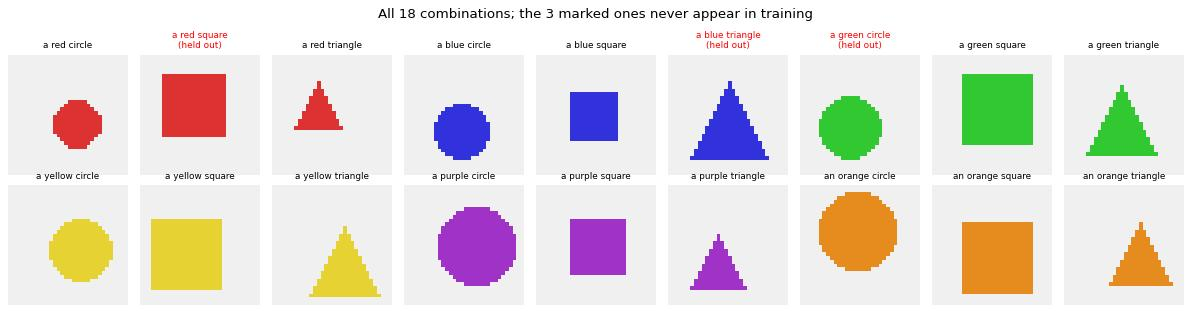

In [3]:
COLORS = ['red', 'blue', 'green', 'yellow', 'purple', 'orange']
SHAPES = ['circle', 'square', 'triangle']
COLOR_RGB = {
    'red': (220, 50, 50), 'blue': (50, 50, 220), 'green': (50, 200, 50),
    'yellow': (230, 210, 50), 'purple': (160, 50, 200), 'orange': (230, 140, 30),
}
BACKGROUND = (240, 240, 240)
HELD_OUT = [('red', 'square'), ('blue', 'triangle'), ('green', 'circle')]
SEEN = [(c, s) for c in COLORS for s in SHAPES if (c, s) not in HELD_OUT]

def caption(color, shape):
    article = 'an' if color[0] in 'aeiou' else 'a'
    return f"{article} {color} {shape}"

def draw_shape(color, shape, rng, size=IMG_SIZE):
    img = Image.new('RGB', (size, size), BACKGROUND)
    d = ImageDraw.Draw(img)
    cx, cy = size // 2 + rng.randint(-4, 4), size // 2 + rng.randint(-4, 4)
    r = rng.randint(6, 10)
    fill = COLOR_RGB[color]
    if shape == 'circle':
        d.ellipse([cx - r, cy - r, cx + r, cy + r], fill=fill)
    elif shape == 'square':
        d.rectangle([cx - r, cy - r, cx + r, cy + r], fill=fill)
    else:
        d.polygon([(cx, cy - r), (cx - r, cy + r), (cx + r, cy + r)], fill=fill)
    return torch.from_numpy(np.asarray(img, dtype=np.float32) / 255.0).permute(2, 0, 1)

def make_set(combos, n_per_combo, seed):
    rng = random.Random(seed)
    imgs, caps = [], []
    for color, shape in combos:
        for _ in range(n_per_combo):
            imgs.append(draw_shape(color, shape, rng))
            caps.append(caption(color, shape))
    return torch.stack(imgs), caps

train_imgs, train_caps = make_set(SEEN, N_PER_COMBO_TRAIN, seed=1)
test_seen_imgs, test_seen_caps = make_set(SEEN, N_PER_COMBO_TEST, seed=2)
test_held_imgs, test_held_caps = make_set(HELD_OUT, N_PER_COMBO_TEST, seed=3)
print(f"Training images: {len(train_imgs)} ({len(SEEN)} seen combinations x {N_PER_COMBO_TRAIN})")
print(f"Test images: {len(test_seen_imgs)} of seen combinations, {len(test_held_imgs)} of held-out combinations")
print("Held-out captions:", [caption(c, s) for c, s in HELD_OUT])
assert not set(train_caps) & set(test_held_caps)

fig, axes = plt.subplots(2, 9, figsize=(15, 4))
for k, (ax, (c, s)) in enumerate(zip(axes.flat, [(c, s) for c in COLORS for s in SHAPES])):
    rng = random.Random(k)
    ax.imshow(draw_shape(c, s, rng).permute(1, 2, 0).numpy())
    held = (c, s) in HELD_OUT
    ax.set_title(caption(c, s) + ("\n(held out)" if held else ""), fontsize=8, color='red' if held else 'black')
    ax.axis('off')
plt.suptitle("All 18 combinations; the 3 marked ones never appear in training")
plt.tight_layout()
plt.show()

## 4. Stage 1: Discrete VAE with the Gumbel-Softmax Relaxation

The encoder outputs, for each of the 8×8 grid cells, 128 logits: one score per codebook entry. During training, a **gumbel-softmax** sample turns these logits into a "soft" one-hot vector, which becomes exactly one-hot as the temperature τ goes to 0. The decoder starts with a 1×1 convolution over these 128 channels, which is the same as looking up (or mixing) codebook vectors, and then upsamples back to 32×32.

As in the paper (Section 2.1 and Appendix A.2):
- τ is annealed from 1 to 1/16 with a cosine schedule (here over the first half of training);
- a KL term pulls each cell's code distribution towards a uniform prior over the 128 codes; its weight rises quickly from 0 at the start;
- the encoder ends, and the decoder starts, with 1×1 convolutions.

The KL weight matters. The paper found that a large KL weight (β = 6.6) gives better codebook use (Section 2.1). In test runs of this notebook with the KL weight at 0, 0.01 or 0.02 instead of 0.5, every grid cell collapsed onto a single code within the first epochs, so the decoder could only draw the average image. Training is still fragile: a test run with 512 codes instead of 128 collapsed even with the weight at 0.5. The paper uses a logit-Laplace likelihood for the pixels; we use a Gaussian one (mean-squared error divided by 2σ², with σ = 0.1). To encode an image for stage 2 we take the **argmax** of the logits, without gumbel noise, as in Section 2.2.

In [4]:
class DiscreteVAE(nn.Module):
    def __init__(self, n_codes=N_CODES, hidden=128):
        super().__init__()
        self.n_codes = n_codes
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, 4, stride=2, padding=1), nn.ReLU(),        # 32 -> 16
            nn.Conv2d(64, hidden, 4, stride=2, padding=1), nn.ReLU(),   # 16 -> 8
            nn.Conv2d(hidden, hidden, 3, padding=1), nn.ReLU(),
            nn.Conv2d(hidden, n_codes, 1),                              # 1x1 conv -> 128 logits per cell
        )
        self.decoder = nn.Sequential(
            nn.Conv2d(n_codes, hidden, 1), nn.ReLU(),                   # 1x1 conv = codebook lookup
            nn.Conv2d(hidden, hidden, 3, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(hidden, 64, 4, stride=2, padding=1), nn.ReLU(),   # 8 -> 16
            nn.ConvTranspose2d(64, 3, 4, stride=2, padding=1),                    # 16 -> 32
            nn.Sigmoid(),
        )

    def forward(self, x, tau):
        logits = self.encoder(x)                                   # (B, 128, 8, 8)
        soft_one_hot = F.gumbel_softmax(logits, tau=tau, dim=1)    # relaxed sample of the codes
        recon = self.decoder(soft_one_hot)
        # KL(q || uniform) per grid cell = sum_k q_k log(q_k * K)
        log_q = F.log_softmax(logits, dim=1)
        kl = (log_q.exp() * (log_q + math.log(self.n_codes))).sum(1).mean()
        return recon, kl

    @torch.no_grad()
    def encode(self, x):
        return self.encoder(x).argmax(1)                           # (B, 8, 8) token ids, no gumbel noise

    @torch.no_grad()
    def decode(self, tokens):
        one_hot = F.one_hot(tokens, self.n_codes).permute(0, 3, 1, 2).float()
        return self.decoder(one_hot)

dvae = DiscreteVAE(hidden=DVAE_HIDDEN).to(device)
print(f"dVAE parameters: {sum(p.numel() for p in dvae.parameters()):,}")

dVAE parameters: 1,776,899


In [5]:
def cosine(start, end, frac):
    return end + (start - end) * 0.5 * (1 + math.cos(math.pi * min(frac, 1.0)))

g = torch.Generator().manual_seed(SEED)
dvae_loader = DataLoader(TensorDataset(train_imgs), batch_size=BATCH_SIZE, shuffle=True, generator=g)
opt = torch.optim.Adam(dvae.parameters(), lr=DVAE_LR)
total_steps = DVAE_EPOCHS * len(dvae_loader)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, total_steps)

@torch.no_grad()
def hard_mse(model, imgs):
    """Reconstruction error with hard argmax codes, the way images are encoded for stage 2."""
    model.eval()
    errs = [F.mse_loss(model.decode(model.encode(b.to(device))), b.to(device), reduction='sum').item()
            for b in imgs.split(256)]
    model.train()
    return sum(errs) / imgs.numel()

dvae_log = []
step = 0
t0 = time.time()
dvae.train()
for epoch in range(DVAE_EPOCHS):
    sums = np.zeros(2)
    for (x,) in dvae_loader:
        x = x.to(device)
        frac = step / total_steps
        tau = cosine(TAU_START, TAU_END, frac / TAU_ANNEAL_FRAC)
        kl_w = KL_WEIGHT_MAX * cosine(0.0, 1.0, frac / KL_WARMUP_FRAC)
        recon, kl = dvae(x, tau)
        mse = F.mse_loss(recon, x)
        loss = RECON_WEIGHT * mse + kl_w * kl
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        step += 1
        sums += [mse.item(), kl.item()]
    sums /= len(dvae_loader)
    test_mse = hard_mse(dvae, test_seen_imgs)
    dvae_log.append((sums[0], sums[1], test_mse, tau))
    if epoch % 10 == 9 or epoch == 0:
        print(f"Epoch {epoch+1:2d}/{DVAE_EPOCHS}  train MSE (soft codes) {sums[0]:.5f}  KL/cell {sums[1]:.3f}  "
              f"test MSE (hard codes) {test_mse:.5f}  tau {tau:.3f}")
print(f"dVAE training took {time.time() - t0:.0f} s")

Epoch  1/60  train MSE (soft codes) 0.08103  KL/cell 0.466  test MSE (hard codes) 0.06945  tau 0.998


Epoch 10/60  train MSE (soft codes) 0.01104  KL/cell 0.247  test MSE (hard codes) 0.01799  tau 0.767


Epoch 20/60  train MSE (soft codes) 0.00860  KL/cell 0.384  test MSE (hard codes) 0.00814  tau 0.298


Epoch 30/60  train MSE (soft codes) 0.00753  KL/cell 0.523  test MSE (hard codes) 0.00594  tau 0.063


Epoch 40/60  train MSE (soft codes) 0.00670  KL/cell 0.529  test MSE (hard codes) 0.00521  tau 0.062


Epoch 50/60  train MSE (soft codes) 0.00645  KL/cell 0.525  test MSE (hard codes) 0.00524  tau 0.062


Epoch 60/60  train MSE (soft codes) 0.00634  KL/cell 0.528  test MSE (hard codes) 0.00508  tau 0.062
dVAE training took 64 s


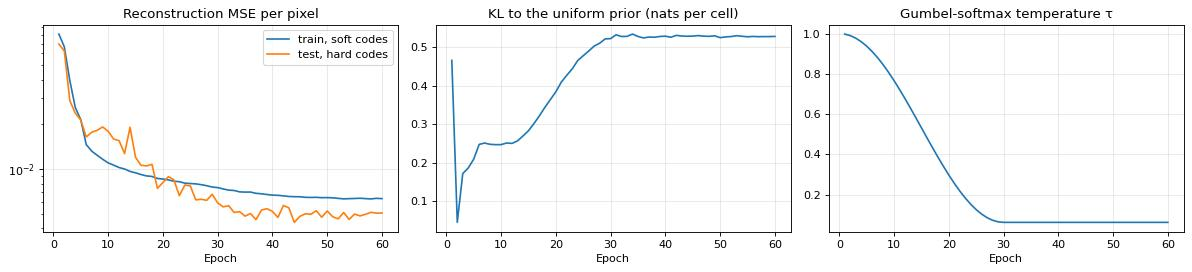

In [6]:
log = np.array(dvae_log)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(range(1, DVAE_EPOCHS + 1), log[:, 0], label='train, soft codes')
axes[0].plot(range(1, DVAE_EPOCHS + 1), log[:, 2], label='test, hard codes')
axes[0].set_yscale('log'); axes[0].set_title('Reconstruction MSE per pixel'); axes[0].legend()
axes[1].plot(range(1, DVAE_EPOCHS + 1), log[:, 1]); axes[1].set_title('KL to the uniform prior (nats per cell)')
axes[2].plot(range(1, DVAE_EPOCHS + 1), log[:, 3]); axes[2].set_title('Gumbel-softmax temperature τ')
for ax in axes: ax.set_xlabel('Epoch'); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### dVAE reconstructions and codebook use

The reconstructions below use hard argmax codes. The held-out combinations were never seen by the dVAE either, so they also show whether the codes describe colours and shapes in general.

Test reconstruction MSE per pixel (hard codes): seen combinations 0.00508, held-out combinations 0.00693


Codebook use on the training images: 123 of 128 codes


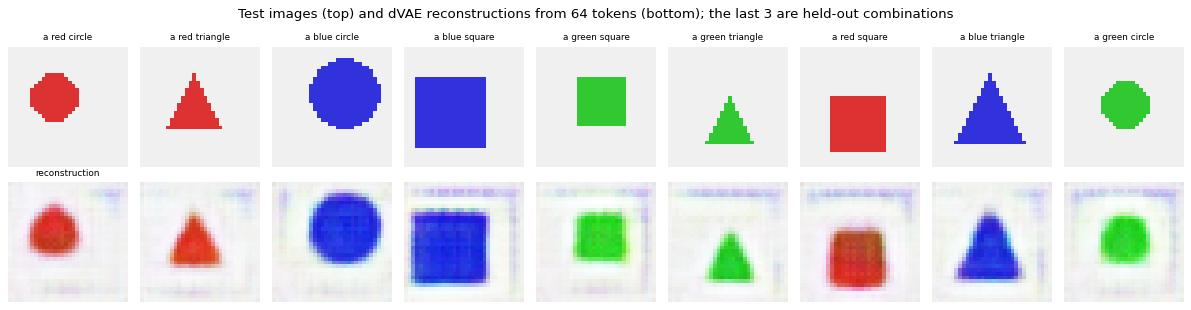

In [7]:
dvae.eval()
mse_seen = hard_mse(dvae, test_seen_imgs)
mse_held = hard_mse(dvae, test_held_imgs)
print(f"Test reconstruction MSE per pixel (hard codes): seen combinations {mse_seen:.5f}, held-out combinations {mse_held:.5f}")
recon_seen = torch.cat([dvae.decode(dvae.encode(b.to(device))).cpu() for b in test_seen_imgs.split(256)])
recon_held = torch.cat([dvae.decode(dvae.encode(b.to(device))).cpu() for b in test_held_imgs.split(256)])

train_tokens = torch.cat([dvae.encode(b.to(device)).cpu() for b in train_imgs.split(256)]).view(len(train_imgs), -1)
used = torch.bincount(train_tokens.flatten(), minlength=N_CODES)
print(f"Codebook use on the training images: {(used > 0).sum().item()} of {N_CODES} codes")

idx_seen = list(range(0, len(test_seen_imgs), N_PER_COMBO_TEST))[:6]
idx_held = list(range(0, len(test_held_imgs), N_PER_COMBO_TEST))
fig, axes = plt.subplots(2, 9, figsize=(15, 4))
for j, (imgs, recs, caps, i) in enumerate([(test_seen_imgs, recon_seen, test_seen_caps, i) for i in idx_seen] +
                                          [(test_held_imgs, recon_held, test_held_caps, i) for i in idx_held]):
    axes[0, j].imshow(imgs[i].permute(1, 2, 0).numpy()); axes[0, j].set_title(caps[i], fontsize=8)
    axes[1, j].imshow(recs[i].clamp(0, 1).permute(1, 2, 0).numpy())
    axes[0, j].axis('off'); axes[1, j].axis('off')
axes[1, 0].set_title('reconstruction', fontsize=8)
plt.suptitle("Test images (top) and dVAE reconstructions from 64 tokens (bottom); the last 3 are held-out combinations")
plt.tight_layout()
plt.show()

## 5. A Checker for Colour and Shape

To measure whether a generated image matches its caption, we need something that reads its colour and shape. The paper ranks samples with CLIP, a large learned model; we use a small checker and no reranking.

- **Colour:** pixels far from the background colour are the shape; their mean colour is matched to the nearest of the 6 colours. This is a fixed rule.
- **Shape:** a small CNN looks only at the black-and-white outline of the shape (which pixels are not background), so it cannot use colour. It is trained on the training images and on their dVAE reconstructions, because generated images have the same soft edges as reconstructions. It never sees the held-out combinations.

The checker is then tested on real test images and on their reconstructions, including the held-out combinations.

In [8]:
PALETTE = torch.tensor([COLOR_RGB[c] for c in COLORS], dtype=torch.float32) / 255.0
BG = torch.tensor(BACKGROUND, dtype=torch.float32) / 255.0

def foreground(imgs):
    # (N, 3, 32, 32) -> (N, 32, 32) mask of pixels clearly different from the background
    return (imgs.clamp(0, 1) - BG[None, :, None, None]).abs().sum(1) > 0.3

shape_net = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(32 * 8 * 8, 64), nn.ReLU(), nn.Linear(64, len(SHAPES)),
).to(device)

recon_train = torch.cat([dvae.decode(dvae.encode(b.to(device))).cpu() for b in train_imgs.split(256)])
shape_x = foreground(torch.cat([train_imgs, recon_train])).float().unsqueeze(1)
shape_y = torch.tensor([SHAPES.index(c.split()[-1]) for c in train_caps] * 2)
g = torch.Generator().manual_seed(SEED)
loader = DataLoader(TensorDataset(shape_x, shape_y), batch_size=BATCH_SIZE, shuffle=True, generator=g)
opt = torch.optim.Adam(shape_net.parameters(), lr=1e-3)
for epoch in range(5):
    for xb, yb in loader:
        loss = F.cross_entropy(shape_net(xb.to(device)), yb.to(device))
        opt.zero_grad(); loss.backward(); opt.step()
shape_net.eval()

@torch.no_grad()
def check_images(imgs):
    # Return a list of (colour, shape) read from (N, 3, 32, 32) images; (None, None) if no shape is visible
    fg = foreground(imgs)
    shapes = shape_net(fg.float().unsqueeze(1).to(device)).argmax(1).cpu()
    out = []
    for img, m, sh in zip(imgs.clamp(0, 1), fg, shapes):
        if m.sum() < 20:
            out.append((None, None))
            continue
        mean_rgb = img[:, m].mean(1)
        out.append((COLORS[int(((PALETTE - mean_rgb) ** 2).sum(1).argmin())], SHAPES[int(sh)]))
    return out

def checker_accuracy(imgs, caps):
    return np.mean([r[0] is not None and caption(*r) == c for r, c in zip(check_images(imgs), caps)])

print("Checker accuracy (colour and shape both right):")
print(f"  real test images:       seen combinations {checker_accuracy(test_seen_imgs, test_seen_caps):.3f}, "
      f"held-out {checker_accuracy(test_held_imgs, test_held_caps):.3f}")
print(f"  dVAE reconstructions:   seen combinations {checker_accuracy(recon_seen, test_seen_caps):.3f}, "
      f"held-out {checker_accuracy(recon_held, test_held_caps):.3f}")

Checker accuracy (colour and shape both right):
  real test images:       seen combinations 1.000, held-out 1.000
  dVAE reconstructions:   seen combinations 0.940, held-out 0.875


## 6. Stage 2: Transformer over Text and Image Tokens

Each caption has exactly three words, so the text part is a start token followed by three word tokens. The 64 image tokens follow, in raster order, and are offset by the size of the text vocabulary so text and image share one vocabulary. The paper uses up to 256 BPE tokens from a vocabulary of 16,384, then 1024 image tokens from 8192 codes.

The model is a standard decoder-only transformer with a causal mask, so every image token can attend to all text tokens and all earlier image tokens. The paper also uses row, column and convolutional attention masks for image-to-image attention; we use the plain causal mask. As in Section 2.2, the cross-entropy losses for text and image tokens are averaged separately and weighted 1/8 and 7/8.

In [9]:
WORDS = ['a', 'an'] + COLORS + SHAPES
BOS = 0
WORD_ID = {w: i + 1 for i, w in enumerate(WORDS)}
TEXT_VOCAB = len(WORDS) + 1
TEXT_LEN = 4                                     # [BOS] a/an colour shape
SEQ_LEN = TEXT_LEN + N_IMG_TOKENS                # 68

def encode_text(cap):
    return [BOS] + [WORD_ID[w] for w in cap.split()]

class Block(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, n_heads, dropout=0.1, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d), nn.Dropout(0.1))

    def forward(self, x, mask):
        h = self.ln1(x)
        x = x + self.attn(h, h, h, attn_mask=mask, need_weights=False)[0]
        return x + self.mlp(self.ln2(x))

class TextImageTransformer(nn.Module):
    def __init__(self, d=D_MODEL, n_layers=N_LAYERS, n_heads=N_HEADS):
        super().__init__()
        self.vocab = TEXT_VOCAB + N_CODES
        self.tok = nn.Embedding(self.vocab, d)
        self.pos = nn.Embedding(SEQ_LEN, d)
        self.blocks = nn.ModuleList([Block(d, n_heads) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, self.vocab)
        self.register_buffer('mask', torch.triu(torch.ones(SEQ_LEN, SEQ_LEN, dtype=torch.bool), 1))

    def forward(self, seq):
        T = seq.shape[1]
        x = self.tok(seq) + self.pos(torch.arange(T, device=seq.device))
        for blk in self.blocks:
            x = blk(x, self.mask[:T, :T])
        return self.head(self.ln(x))

def make_sequences(caps, img_tokens):
    text = torch.tensor([encode_text(c) for c in caps])
    return torch.cat([text, img_tokens + TEXT_VOCAB], dim=1)

train_seq = make_sequences(train_caps, train_tokens)
test_seen_tokens = torch.cat([dvae.encode(b.to(device)).cpu() for b in test_seen_imgs.split(256)]).view(len(test_seen_imgs), -1)
test_seen_seq = make_sequences(test_seen_caps, test_seen_tokens)
print("Example sequence (first 10 of 68 tokens):", train_seq[0, :10].tolist(), "for", repr(train_caps[0]))

model = TextImageTransformer().to(device)
print(f"Transformer parameters: {sum(p.numel() for p in model.parameters()):,}")

Example sequence (first 10 of 68 tokens): [0, 1, 3, 9, 89, 130, 57, 59, 100, 57] for 'a red circle'
Transformer parameters: 3,248,780


Epoch  1/40  text loss 3.6804  image loss 4.5584  test image loss 3.6303


Epoch  5/40  text loss 0.9378  image loss 1.4898  test image loss 1.3883


Epoch 10/40  text loss 0.9195  image loss 0.9543  test image loss 0.9218


Epoch 15/40  text loss 0.9153  image loss 0.7183  test image loss 0.7297


Epoch 20/40  text loss 0.9124  image loss 0.5842  test image loss 0.6259


Epoch 25/40  text loss 0.9108  image loss 0.5032  test image loss 0.5675


Epoch 30/40  text loss 0.9081  image loss 0.4573  test image loss 0.5370


Epoch 35/40  text loss 0.9073  image loss 0.4359  test image loss 0.5249


Epoch 40/40  text loss 0.9072  image loss 0.4295  test image loss 0.5227
Transformer training took 184 s


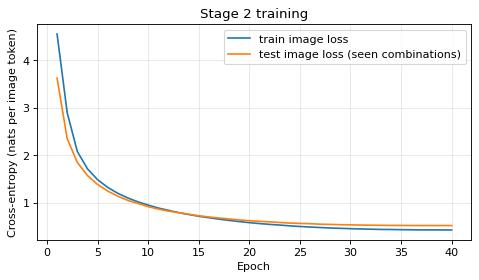

In [10]:
def seq_losses(model, seq):
    logits = model(seq[:, :-1])
    target = seq[:, 1:]
    ce = F.cross_entropy(logits.reshape(-1, model.vocab), target.reshape(-1), reduction='none').view(target.shape)
    n_text = TEXT_LEN - 1                        # targets 1..3 are words, the rest are image tokens
    return ce[:, :n_text].mean(), ce[:, n_text:].mean()

g = torch.Generator().manual_seed(SEED)
tf_loader = DataLoader(TensorDataset(train_seq), batch_size=BATCH_SIZE, shuffle=True, generator=g)
opt = torch.optim.AdamW(model.parameters(), lr=TF_LR, weight_decay=0.01)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=TF_LR, total_steps=TF_EPOCHS * len(tf_loader), pct_start=0.05)

tf_log = []
t0 = time.time()
for epoch in range(TF_EPOCHS):
    model.train()
    sums = np.zeros(2)
    for (seq,) in tf_loader:
        seq = seq.to(device)
        text_loss, img_loss = seq_losses(model, seq)
        loss = TEXT_LOSS_WEIGHT * text_loss + IMAGE_LOSS_WEIGHT * img_loss
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()
        sums += [text_loss.item(), img_loss.item()]
    sums /= len(tf_loader)
    model.eval()
    with torch.no_grad():
        test_img_loss = seq_losses(model, test_seen_seq.to(device))[1].item()
    tf_log.append((sums[0], sums[1], test_img_loss))
    if epoch % 5 == 4 or epoch == 0:
        print(f"Epoch {epoch+1:2d}/{TF_EPOCHS}  text loss {sums[0]:.4f}  image loss {sums[1]:.4f}  "
              f"test image loss {test_img_loss:.4f}")
print(f"Transformer training took {time.time() - t0:.0f} s")

log = np.array(tf_log)
plt.figure(figsize=(7, 3.5))
plt.plot(range(1, TF_EPOCHS + 1), log[:, 1], label='train image loss')
plt.plot(range(1, TF_EPOCHS + 1), log[:, 2], label='test image loss (seen combinations)')
plt.xlabel('Epoch'); plt.ylabel('Cross-entropy (nats per image token)'); plt.legend(); plt.grid(True, alpha=0.3)
plt.title('Stage 2 training')
plt.show()

## 7. Generating Images from Captions

For a caption, the transformer gets the 4 text tokens and samples the 64 image tokens one at a time, at temperature 1 and only from the image part of the vocabulary. The dVAE decoder turns the tokens into a 32×32 image.

Generated 32 images for each of 18 captions in 7 s


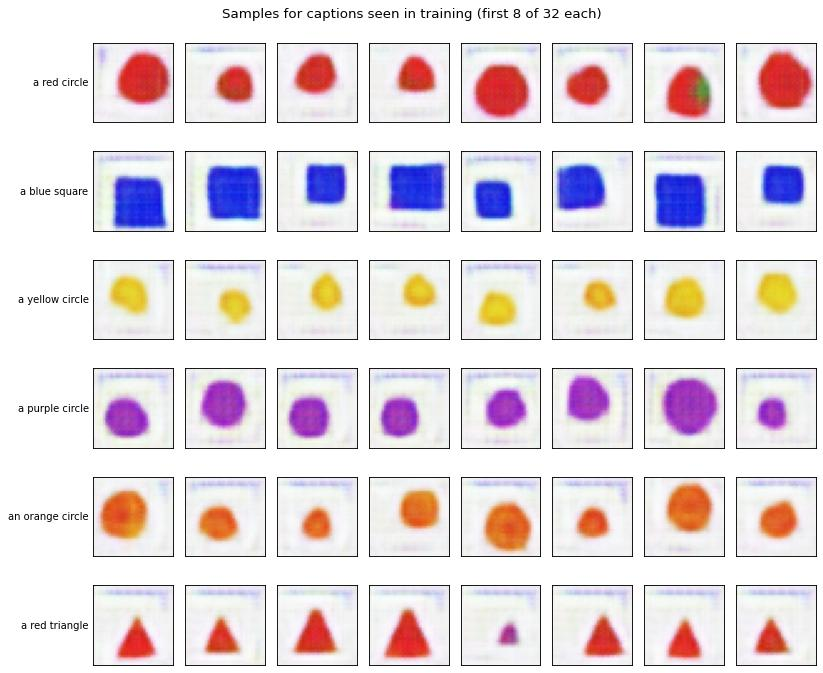

In [11]:
@torch.no_grad()
def generate(model, caps, gen):
    model.eval()
    seq = torch.tensor([encode_text(c) for c in caps], device=device)
    for _ in range(N_IMG_TOKENS):
        logits = model(seq)[:, -1, TEXT_VOCAB:]               # image tokens only
        probs = F.softmax(logits.float(), dim=-1)
        nxt = torch.multinomial(probs.cpu(), 1, generator=gen).to(device)
        seq = torch.cat([seq, nxt + TEXT_VOCAB], dim=1)
    tokens = (seq[:, TEXT_LEN:] - TEXT_VOCAB).view(-1, GRID, GRID)
    return dvae.decode(tokens).cpu()

gen = torch.Generator().manual_seed(SEED)
all_combos = [(c, s) for c in COLORS for s in SHAPES]
samples = {}
t0 = time.time()
for c, s in all_combos:
    samples[(c, s)] = generate(model, [caption(c, s)] * SAMPLES_PER_PROMPT, gen)
print(f"Generated {SAMPLES_PER_PROMPT} images for each of {len(all_combos)} captions in {time.time() - t0:.0f} s")

def show_samples(combos, title, n=8):
    fig, axes = plt.subplots(len(combos), n, figsize=(n * 1.3, len(combos) * 1.45))
    for r, (c, s) in enumerate(combos):
        for k in range(n):
            ax = axes[r, k]
            ax.imshow(samples[(c, s)][k].clamp(0, 1).permute(1, 2, 0).numpy())
            ax.set_xticks([]); ax.set_yticks([])
        axes[r, 0].set_ylabel(caption(c, s), rotation=0, ha='right', va='center', fontsize=9)
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_samples([cs for cs in SEEN][::3] + [SEEN[1]], "Samples for captions seen in training (first 8 of 32 each)")

## 8. Zero-Shot Test: Captions for Combinations Never Seen in Training

These three captions never appeared in training, but each of their words did, with other partners.

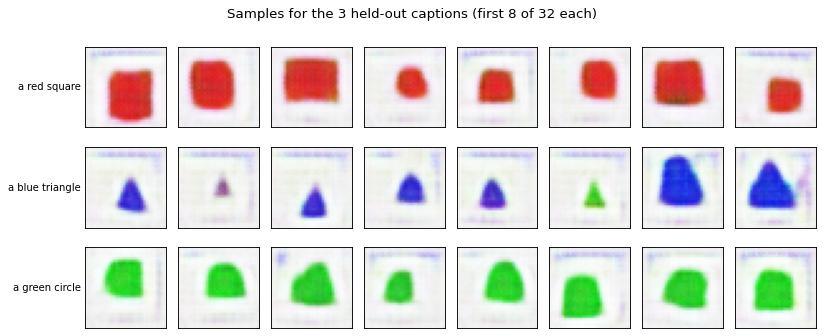

caption                held out  colour ok  shape ok  both ok
a red circle                         1.000     1.000    1.000
a red square                yes      0.906     0.469    0.469
a red triangle                       0.781     1.000    0.781
a blue circle                        1.000     0.906    0.906
a blue square                        0.969     0.906    0.906
a blue triangle             yes      0.531     0.906    0.438
a green circle              yes      1.000     0.688    0.688
a green square                       1.000     1.000    1.000
a green triangle                     1.000     1.000    1.000
a yellow circle                      1.000     1.000    1.000
a yellow square                      1.000     0.688    0.688
a yellow triangle                    1.000     1.000    1.000
a purple circle                      1.000     1.000    1.000
a purple square                      1.000     0.844    0.844
a purple triangle                    1.000     0.969    0.969
an orang

In [12]:
show_samples(HELD_OUT, "Samples for the 3 held-out captions (first 8 of 32 each)")

def score(combo):
    reads = check_images(samples[combo])
    color_ok = np.mean([r[0] == combo[0] for r in reads])
    shape_ok = np.mean([r[1] == combo[1] for r in reads])
    both_ok = np.mean([r == combo for r in reads])
    return color_ok, shape_ok, both_ok

print(f"{'caption':<22}{'held out':>9}{'colour ok':>11}{'shape ok':>10}{'both ok':>9}")
rows = {}
for combo in all_combos:
    rows[combo] = score(combo)
    held = 'yes' if combo in HELD_OUT else ''
    print(f"{caption(*combo):<22}{held:>9}{rows[combo][0]:>11.3f}{rows[combo][1]:>10.3f}{rows[combo][2]:>9.3f}")

seen_mean = np.mean([rows[c] for c in SEEN], axis=0)
held_mean = np.mean([rows[c] for c in HELD_OUT], axis=0)
print(f"\nMean over the 15 seen captions:    colour {seen_mean[0]:.3f}  shape {seen_mean[1]:.3f}  both {seen_mean[2]:.3f}")
print(f"Mean over the 3 held-out captions: colour {held_mean[0]:.3f}  shape {held_mean[1]:.3f}  both {held_mean[2]:.3f}")
print(f"Chance level for 'both' with a random colour and shape: {1/18:.3f}")

### What did the model draw instead?

For each held-out caption, the most common (colour, shape) the checker read from the 32 samples.

In [13]:
from collections import Counter
for combo in HELD_OUT:
    counts = Counter(check_images(samples[combo]))
    top = ', '.join(f"{caption(*k) if None not in k else 'unclear'}: {v}" for k, v in counts.most_common(4))
    print(f"{caption(*combo):<16} -> {top}")

a red square     -> a red square: 15, a red circle: 13, an orange triangle: 2, an orange circle: 1
a blue triangle  -> a blue triangle: 14, a purple triangle: 13, a blue circle: 3, a yellow triangle: 1
a green circle   -> a green circle: 22, a green square: 8, a green triangle: 2


## 9. Summary

### What the run above shows

- **Stage 1 (dVAE):** with the gumbel-softmax relaxation and a strong KL term, the dVAE learned a usable codebook: 123 of the 128 codes are used, and the test reconstruction error with hard codes fell to 0.0051 per pixel (0.0069 for the held-out combinations, which the dVAE never saw). Reconstructions keep the shape and colour, with softer corners and edges. In test runs with a much weaker KL weight, every grid cell collapsed onto one code.
- **Checker:** it reads colour and shape correctly for all real test images, and for 94.0% of reconstructions of seen combinations and 87.5% of reconstructions of held-out combinations. So it is not perfect on blurry images, and some errors below may be the checker's or the dVAE's rather than the transformer's.
- **Stage 2 (transformer):** the image loss fell from 4.56 to 0.43 nats per token on the training set, and to 0.52 on test images of seen combinations. The text loss stayed at about 0.91 nats per word, which is ln(15)/3 ≈ 0.90: the model cannot predict which of the 15 training captions comes next, as expected.
- **Seen captions:** 92.1% of the generated images have both the right colour and the right shape (colour 97.9%, shape 94.0%).
- **Held-out captions (zero-shot):** 53.1% of the generated images have both right, against 5.6% by chance and 92.1% for seen captions. "A green circle" worked best (68.8%; the rest were mostly green squares). "A red square" gave red squares 46.9% of the time and red circles 41%. "A blue triangle" gave blue triangles 43.8% of the time and purple triangles 41%, so the model got the shape but often mixed blue with purple.

So this tiny model does combine a colour and a shape it never saw together, well above chance, but much less reliably than for combinations it was trained on. This is a toy version of the paper's zero-shot claim, not evidence about DALL-E itself. An earlier version of this notebook trained a VQ-VAE-style model whose loss rose during training and used only 34 of its 128 codes, so its images were noise; and its "zero-shot" captions were all in the training data.

### What the real DALL-E has that this notebook does not

- 256×256 images, a dVAE with 8192 codes and 1024 image tokens, and a logit-Laplace pixel likelihood (Sections 2.1 and Appendix A).
- A 12-billion-parameter sparse transformer with 64 layers and row, column and convolutional attention masks, trained on 250 million text-image pairs (Sections 2.2 and 2.3).
- BPE captions of up to 256 tokens from a vocabulary of 16,384, with a learned padding token for each text position (Section 2.2).
- Reranking: many samples are drawn for each caption and a pretrained contrastive model (CLIP) picks the best; the paper's results use 512 samples per caption (Section 2.6).